In [1]:
import keras
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D,Dense, Flatten
from keras.utils import to_categorical
from keras.datasets import mnist
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
     

In [2]:
(xtrain,ytrain),(xtest,ytest)=mnist.load_data()

In [3]:
xtrain=xtrain.reshape((xtrain.shape[0],28,28,1))
xtest=xtest.reshape((xtest.shape[0],28,28,1))

In [4]:
train_norm = xtrain.astype('float32')
test_norm = xtest.astype('float32')
xtrain = train_norm/255.0
xtest = test_norm/255.0

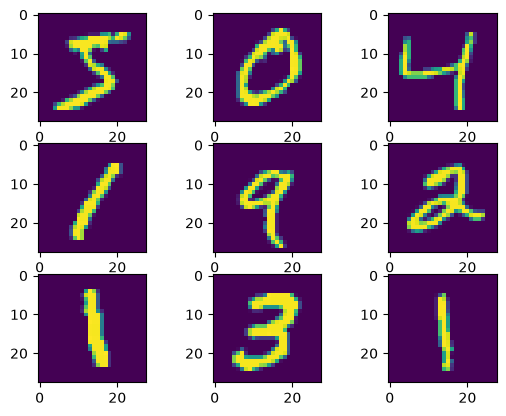

In [5]:
for i in range(9):
  plt.subplot(330+1+i)
  plt.imshow(xtrain[i])

In [6]:
model = Sequential()
model.add(Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)))
model.add(MaxPooling2D(2,2))
model.add(Flatten())
model.add(Dense(100,activation='relu'))
model.add(Dense(10,activation='softmax'))

C:\Users\HP\dl-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [7]:
model.compile(optimizer='sgd',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [8]:
history=model.fit(xtrain,ytrain,epochs=5,validation_data=(xtest,ytest))

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 39s 20ms/step - accuracy: 0.8773 - loss: 0.4532 - val_accuracy: 0.9277 - val_loss: 0.2432
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 39s 19ms/step - accuracy: 0.9358 - loss: 0.2184 - val_accuracy: 0.9491 - val_loss: 0.1739
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - accuracy: 0.9507 - loss: 0.1681 - val_accuracy: 0.9566 - val_loss: 0.1459
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 43s 18ms/step - accuracy: 0.9600 - loss: 0.1373 - val_accuracy: 0.9626 - val_loss: 0.1229
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 15ms/step - accuracy: 0.9649 - loss: 0.1174 - val_accuracy: 0.9686 - val_loss: 0.1054


In [9]:
predictions =model.predict(xtest)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


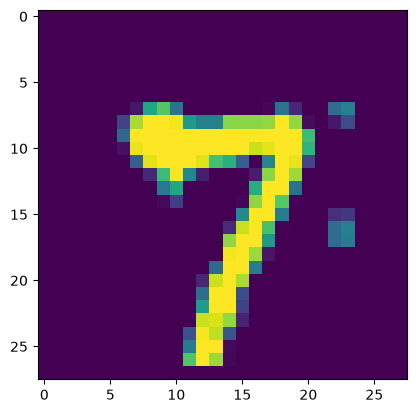

In [10]:
import random
index = random.randint(1,10000)
plt.imshow(xtest[index])

In [11]:
pred_num = max(predictions[index])
for i in range(len(predictions[index])):
    if(predictions[index][i] == pred_num):
        print("Predicted number is: ",i)
        break

Predicted number is:  7


In [12]:
print(model.evaluate(xtest,ytest))

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9686 - loss: 0.1054
[0.10536052286624908, 0.9685999751091003]


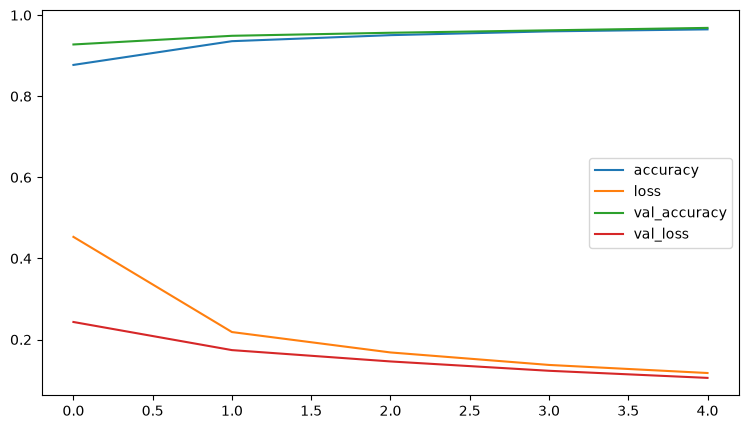

In [13]:
import pandas as pd
pd.DataFrame(history.history).plot(figsize=(9,5))
plt.show()

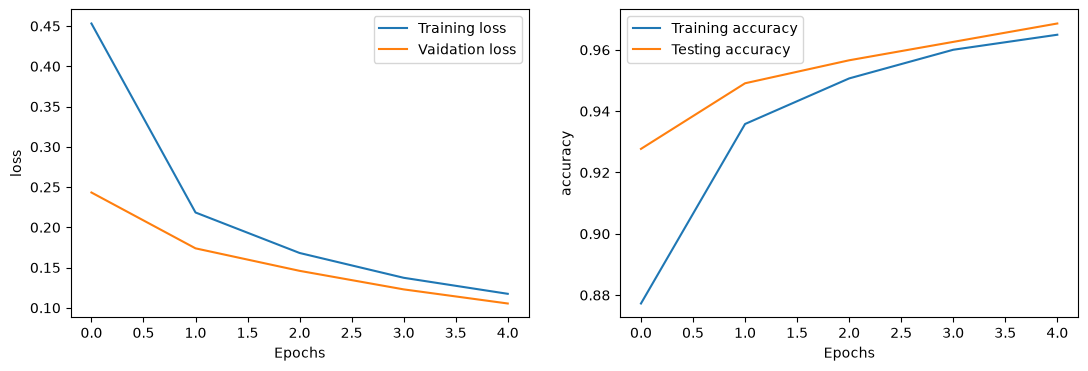

In [14]:
plt.figure(figsize=(13,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'],label='Training loss')
plt.plot(history.history['val_loss'],label='Vaidation loss')
plt.xlabel('Epochs')
plt.ylabel('loss')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'],label='Training accuracy')
plt.plot(history.history['val_accuracy'],label='Testing accuracy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.legend()